In [ ]:
# Uncomment when runing on Kaggle

# %%writefile data_utils.py
# from torch.utils.data import Dataset

# class ApplyTransform(Dataset):
#     def __init__(self, subset, transform=None):
#         self.subset = subset
#         self.transform = transform

#     def __getitem__(self, index):
#         x, y = self.subset[index]
#         if self.transform:
#             x0 = self.transform(x)
#             x1 = self.transform(x)
#         else:
#             x0 = x
#             x1 = x
#         return (x0, x1), y
#     def __len__(self):
#         return len(self.subset)

# class StandardTransform(Dataset):
    
#     def __init__(self, subset, transform=None):
#         self.subset = subset
#         self.transform = transform

#     def __getitem__(self, index):
#         x, y = self.subset[index]
#         if self.transform:
#             x = self.transform(x)
#         return x, y

#     def __len__(self):
#         return len(self.subset)

In [1]:
import os
import sys

sys.path.append(os.path.abspath(".."))
import torch
import torchvision
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Dataset, random_split, Subset
import torch.utils.data as data
import wandb
from data_utils import ApplyTransform, StandardTransform
from torchvision import transforms


In [ ]:
#!pip install lightly

In [2]:
from lightly.loss import NTXentLoss
from lightly.models.modules import SimCLRProjectionHead
from lightly.transforms.simclr_transform import SimCLRTransform

In [ ]:
# Uncomment for running on kaggle
"""
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
wandb_key = user_secrets.get_secret("WANDB_KEY")
wandb.login(key=wandb_key)
"""

In [32]:
if os.path.exists("/kaggle/working"):
    base_path = "/kaggle/working"

elif "google.colab" in str(get_ipython()):
    base_path = "/content/drive/MyDrive/ProjectSimCLR"

else:
    base_path = "./"

models_path = os.path.join(base_path, "models")

os.makedirs(models_path, exist_ok=True)


def save_checkpoint(model, optimizer, epoch, loss, run_id, hp):

    torch.save(
        {
            "epoch": epoch,
            "optimizer": optimizer.state_dict(),
            "model": model.state_dict(),
            "loss": loss,
            "wandb_run_id": run_id,
            "hp": hp,
        },
        os.path.join(models_path, f"{run_id}_epoch_{epoch}.pth"),
    )


def load_checkpoint(model, optimizer, path, map_location=None):
    if map_location is None:
        if torch.cuda.is_available():
            map_location = "cuda"
        elif torch.backends.mps.is_available():
            map_location = "mps"
        else:
            map_location = "cpu"
    checkpoint = torch.load(path, weights_only=False, map_location=map_location)
    saved_model = checkpoint["model"]
    saved_optimizer = checkpoint["optimizer"]
    model.load_state_dict(saved_model)
    optimizer.load_state_dict(saved_optimizer)
    return checkpoint["epoch"], checkpoint["loss"], checkpoint["wandb_run_id"] , checkpoint["hp"]

In [4]:
class SimCLR(nn.Module):
    def __init__(self, encoder, projection_head):
        super().__init__()
        self.encoder = encoder
        self.projection_head = projection_head

    def forward(self, x):
        x = self.encoder(x)
        x = torch.flatten(x, 1)
        x = self.projection_head(x)
        return x

In [5]:
resnet = torchvision.models.resnet18()
backbone = nn.Sequential(*list(resnet.children())[:-1])
projection_head = SimCLRProjectionHead(input_dim=512, hidden_dim=512, output_dim=128)
model = SimCLR(backbone, projection_head)

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
model.to(device)

In [6]:
hp = {
    "batch_size": 256,
    "pipeline_test": False,
    "epochs": 50,
    "temperature": 0.2,
    "optim": {"base_lr": 0.06, "weight_decay": 1e-5},
}

In [7]:
train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(32),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
        transforms.RandomGrayscale(p=0.2),
        transforms.ToTensor(),
        transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010]
    )
    ]
)


full_train_dataset = datasets.CIFAR10(root="./data", train=True, download=True)

train_subset, val_subset = random_split(full_train_dataset, [45000, 5000])

train_data = ApplyTransform(train_subset, transform=train_transform)

num_workers = 4

if hp["pipeline_test"]:
    train_data = Subset(train_data, range(512))
    val_subset = Subset(val_subset, range(256))
    hp["epochs"] = 5
    num_workers = 0

/Users/hannesneumann/Repositories/SelfSupervisedLearning/.venv/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [ ]:
dataloader = DataLoader(
    train_data,
    batch_size=hp["batch_size"],
    shuffle=True,
    drop_last=True,
    num_workers=num_workers,
)

In [ ]:
criterion = NTXentLoss(temperature=hp["temperature"])
optimizer = torch.optim.SGD(
    params=model.parameters(),
    lr=hp["optim"]["base_lr"] * hp["batch_size"] / 256,
    weight_decay=hp["optim"]["weight_decay"],
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max = hp["epochs"]
)
# Uncomment when using multiple GPUs
model = torch.nn.DataParallel(model)

In [ ]:
print("Starting Training ...")
run = wandb.init(project="simclr-cifar10", config=hp, mode="online")
model = model.to(device)
for epoch in range(hp["epochs"]):
    print(f"Epoch {epoch} of {hp['epochs']}")
    total_loss = 0
    for batch in dataloader:
        x0, x1 = batch[0]
        x0 = x0.to(device)
        x1 = x1.to(device)
        z0 = model(x0)
        z1 = model(x1)

        loss = criterion(z0, z1)
        total_loss += loss
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    avg_loss = total_loss / len(dataloader)
    wandb.log({"loss": avg_loss, "epoch": epoch, "lr": scheduler.get_last_lr()[0]})
    scheduler.step()
    if epoch % 10 == 0 and epoch >= 20:
        save_checkpoint(model, optimizer, epoch, loss, run.id, hp)
    print(f"Epoch: {epoch}, Avg_loss: {avg_loss:.5f}")
print("Training Completed, saving the model")
save_checkpoint(model, optimizer, epoch, loss, run.id, hp)

In [ ]:
def linear_evaluation(backbone, train_loader, test_loader, device, epochs = 30):
    # Encoder einfrieren
    for param in backbone.parameters():
        param.requires_grad = False

    classifier = nn.Linear(512, 10).to(device)  # 10 CIFAR-10 Klassen
    optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)
    backbone.eval()
    for epoch in range(epochs):
        total_loss = 0
        for imgs, labels in train_loader:
            features = backbone(imgs.to(device))
            features = torch.flatten(features, start_dim=1)
            preds = classifier(features)
            loss = nn.CrossEntropyLoss()(preds, labels.to(device))
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            total_loss += loss
        print(f"Avg Loss: {total_loss / len(train_loader)}")
        wandb.log({"linear_eval_loss": total_loss / len(train_loader)})

    classifier.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            # imgs = imgs[0]
            features = backbone(imgs.to(device))
            features = torch.flatten(features, start_dim=1)
            preds = classifier(features)
            predicted = preds.argmax(dim=1)
            correct += (predicted == labels.to(device)).sum().item()
            total += labels.size(0)
    accuracy = correct / total if total > 0 else 0
    print(f"Accuracy: {accuracy}")
    wandb.log({"linear_eval_accuracy": accuracy})


In [34]:
if torch.cuda.is_available():
    torch_device = torch.device("cuda")
elif torch.backends.mps.is_available():
    torch_device = torch.device("mps")
else:
    torch_device = torch.device("cpu")

resnet = torchvision.models.resnet18()
backbone = nn.Sequential(*list(resnet.children())[:-1])
projection_head = SimCLRProjectionHead(input_dim=512, hidden_dim=512, output_dim=128)
model = SimCLR(backbone, projection_head)
model = torch.nn.DataParallel(model)
optimizer = torch.optim.SGD(
    params=model.named_parameters(),
    lr=hp["optim"]["base_lr"] * hp["batch_size"] / 256,
    weight_decay=hp["optim"]["weight_decay"],
)
epoch, loss, run_id, hp = load_checkpoint(
    model,
    optimizer,
    "models/29ck2mre_epoch_74.pth",
    map_location=torch_device,
)
model.to(torch_device)
print(hp)

{'batch_size': 512, 'pipeline_test': False, 'epochs': 75, 'temperature': 1, 'optim': {'base_lr': 0.06, 'weight_decay': 1e-05}}


In [13]:
linear_transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.4914, 0.4822, 0.4465], std=[0.2023, 0.1994, 0.2010]
        ),
    ]
)
linear_loader = DataLoader(StandardTransform(train_subset, linear_transform), 256)
val_loader = DataLoader(
    StandardTransform(
        val_subset,
        linear_transform,
    )
)
# linear_evaluation(model.module.encoder, linear_loader, val_loader, device, epochs=3)

In [38]:
model_temp1 = model_nojitter = model_temp02 = model

epoch, loss, run_id, hp = load_checkpoint(
    model_temp1,
    optimizer,
    "models/SimCLR_temp1.pth",
    map_location=torch_device,
)
model_temp1.to(torch_device)

epoch, loss, run_id, hp = load_checkpoint(
    model_nojitter,
    optimizer,
    "models/SimCLR_nojitter.pth",
    map_location=torch_device,
)
model_nojitter.to(torch_device)

epoch, loss, run_id, hp = load_checkpoint(
    model_temp02,
    optimizer,
    "models/SimCLR_temp02.pth",
    map_location=torch_device,
)
model_temp02.to(torch_device)

models = {"model_nojitter": model_nojitter, "model_temp1": model_temp1, "model_temp02": model_temp02}


/Users/hannesneumann/Repositories/SelfSupervisedLearning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/hannesneumann/Repositories/SelfSupervisedLearning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


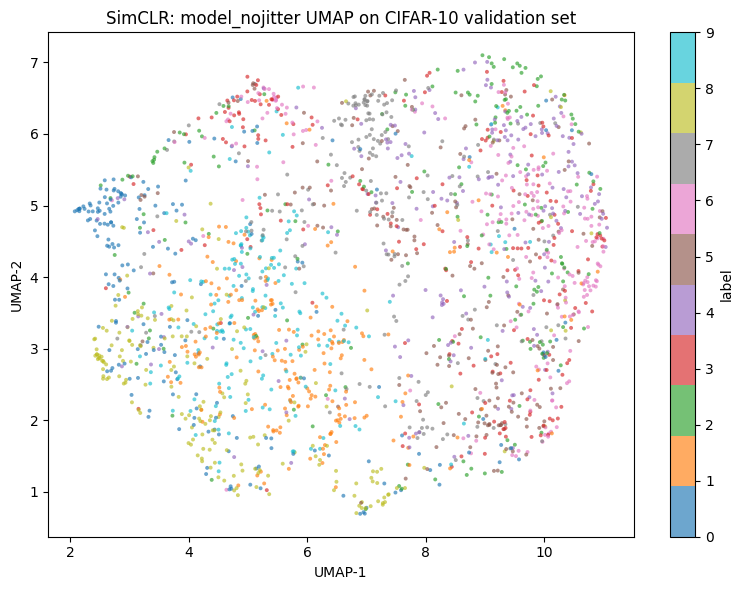

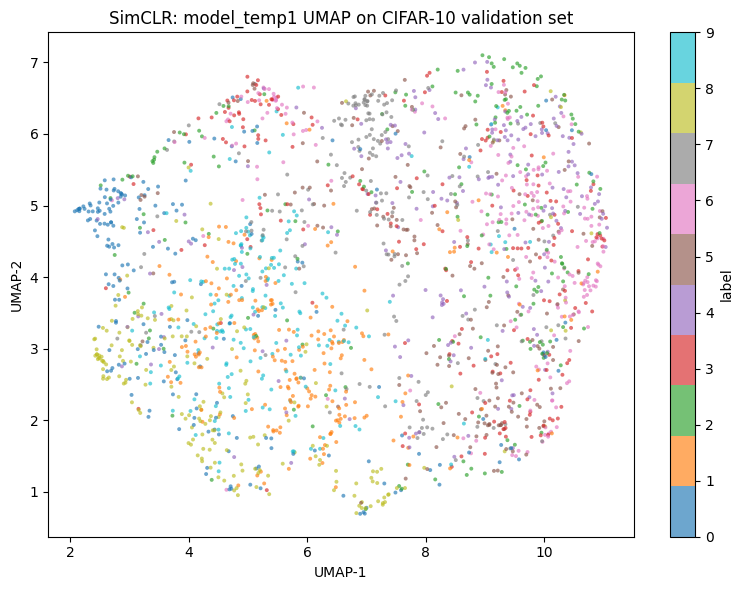

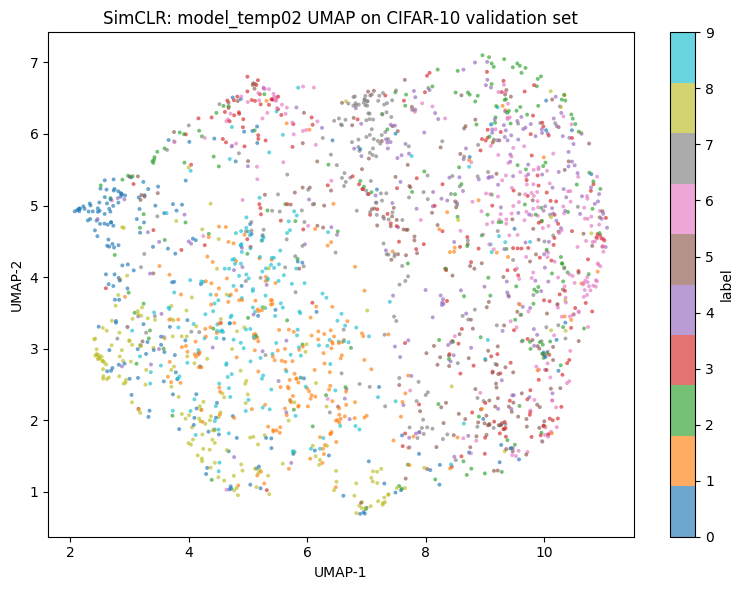

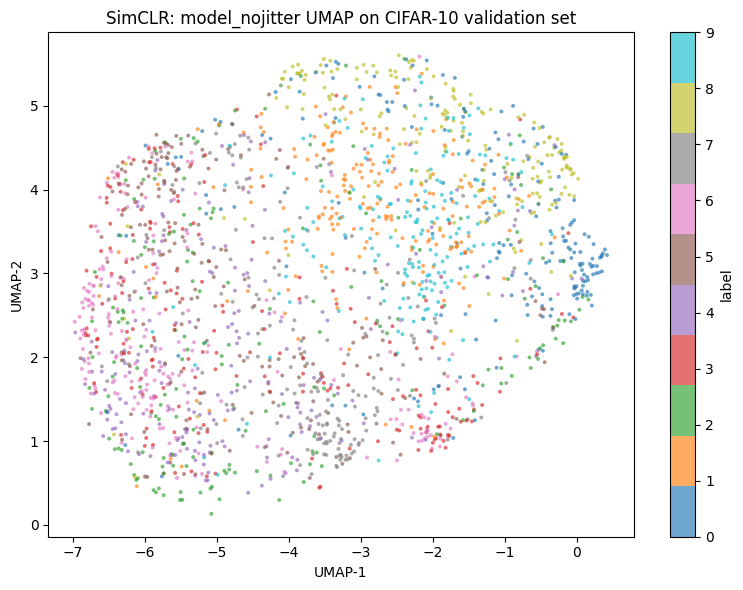

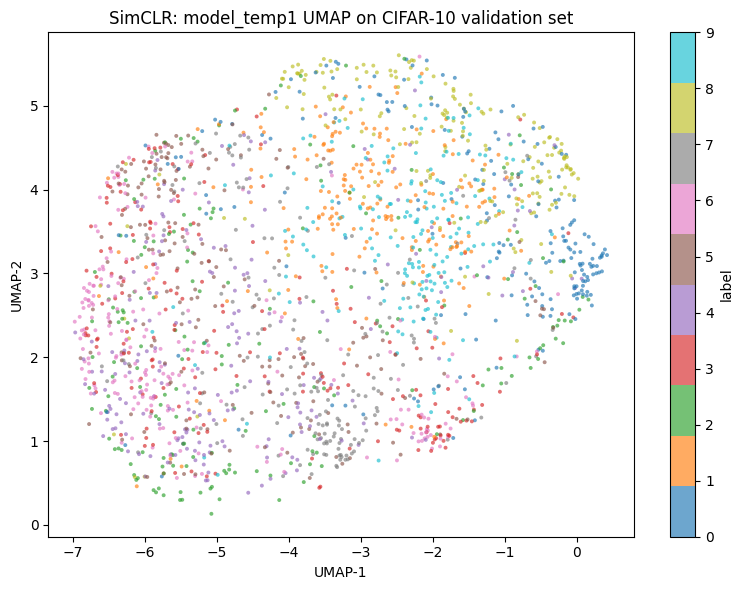

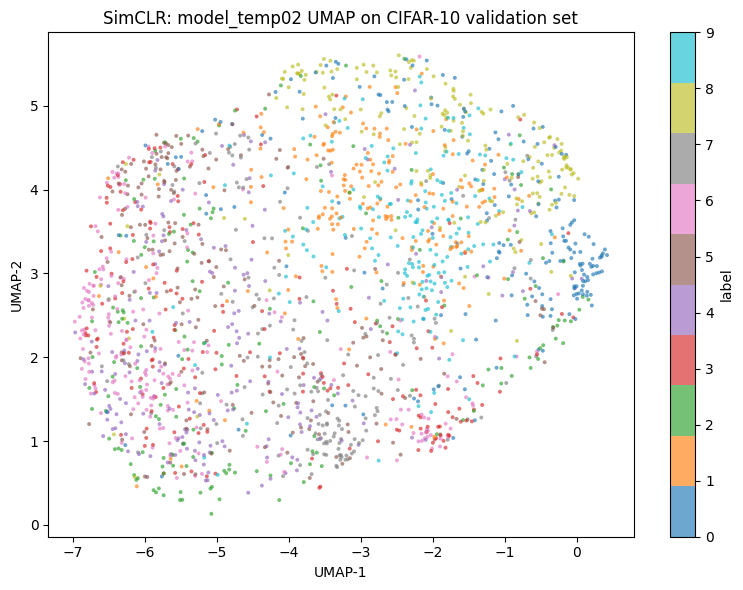

In [ ]:
import matplotlib.pyplot as plt
from src.umap import SimCLRUmapVisualizer

umap_dataset = StandardTransform(val_subset, linear_transform)
visualizer = SimCLRUmapVisualizer(n_neighbors=15, min_dist=0.01, metric="cosine")

for name, model in models.items():
    
    fig = visualizer.visualize(
        model,
        umap_dataset,
        device=torch_device,
        batch_size=256,
        max_samples=2000,
        representation="encoder",
        title=f"SimCLR: {name} UMAP on CIFAR-10 validation set",
    )

visualizer2 = SimCLRUmapVisualizer(n_neighbors=200, min_dist=0.1, metric="cosine")
for name, model in models.items():
    fig2 = visualizer2.visualize(
    model,
    umap_dataset,
    device=torch_device,
    batch_size=256,
    max_samples=2000,
    representation="encoder",
    title=f"SimCLR: {name} UMAP on CIFAR-10 validation set",
    ) 

plt.show()

/Users/hannesneumann/Repositories/SelfSupervisedLearning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


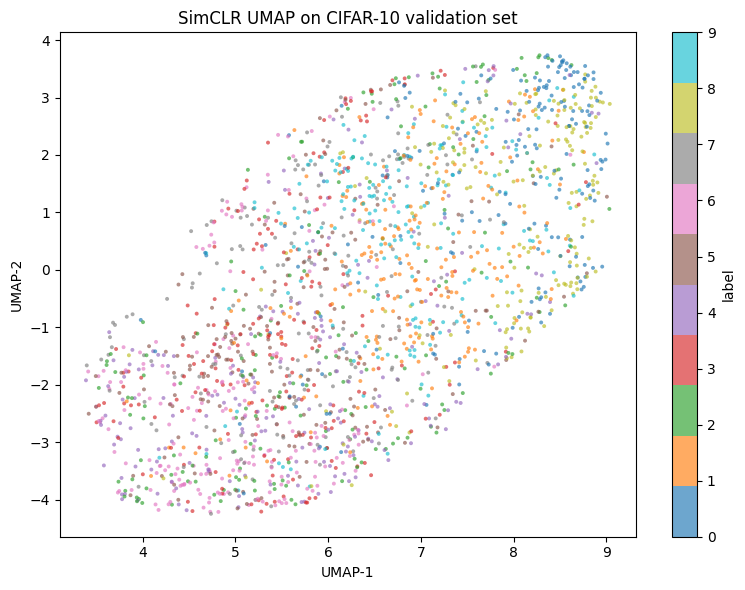

In [23]:

umap_dataset = StandardTransform(val_subset, linear_transform)
visualizer = SimCLRUmapVisualizer(n_neighbors=150, min_dist=0.1, metric="cosine")

fig = visualizer.visualize(
    model,
    umap_dataset,
    device=torch_device,
    batch_size=256,
    max_samples=2000,
    representation="encoder",
    title="SimCLR UMAP on CIFAR-10 validation set",
)

plt.show()

In [ ]:
model2 = model
epoch, loss, run_id = load_checkpoint(
    model2,
    optimizer,
    "models/7dzthk7c_epoch_74.pth",
    map_location=torch_device,
)
model.to(torch_device)


/Users/hannesneumann/Repositories/SelfSupervisedLearning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/hannesneumann/Repositories/SelfSupervisedLearning/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


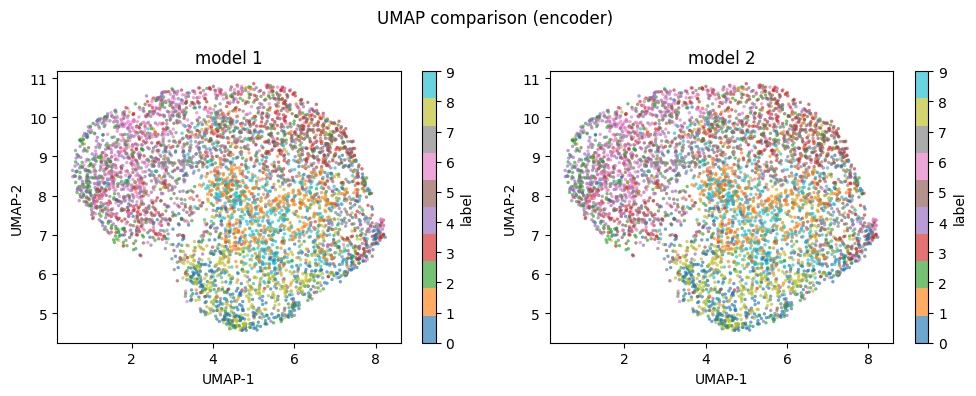

In [31]:
from src.umap import compare_models_umap
umap_dataset = StandardTransform(val_subset, linear_transform)
visualizer = SimCLRUmapVisualizer(n_neighbors=150, min_dist=0.1, metric="cosine")

compare_models_umap(
    {"model 1": model,  "model 2": model2},
    umap_dataset,
    visualizer
)

plt.show()